![Original climate-globe illustration introducing ENSO against a warming ocean; illustrative, not a data map](assets/atlas-splash.png)

# 24 · ENSO against a warming ocean

**Guiding question:** What changes when the tropical background is removed?

**Data:** Real C3S/ECMWF ERA5 Climate Pulse CSV snapshots retrieved 2026-11-20; CC BY 4.0  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-20  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** tables, figures, and any explicitly named local exports; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=24-relative-enso.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

The relative Niño index compares a Niño-region anomaly with a tropical-ocean
        anomaly and applies a region- and month-dependent scaling factor. Removing
        the tropical background changes what the index measures. Scaling preserves a
        useful amplitude range; simply subtracting two anomalies is not the full method.

        This lesson uses **the producer's published relative column**. It does not estimate
        missing tropical means or substitute global SST (whose domain is different).
        Use the linked ECMWF methodology for the equation, scaling conventions, and
        interpretation. A single daily or monthly index value is not, by itself, an operational
        ENSO declaration; consult the responsible monitoring agency and its full criteria.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Compare two explicitly different quantities

In [2]:
from pulse_helpers import (
    load_pulse, complete_months, rank_same_month, region_rings, region_geojson,
    region_map, region_globe, REGIONS, ANOM, REL, CREDIT, BASE,
)
df = load_pulse()
part = df[df.year >= 1979]
fig = go.Figure()
for col, label in [(ANOM, "Traditional anomaly"), (REL, "Published relative index")]:
    fig.add_trace(go.Scatter(x=part.date, y=part[col], name=label, mode="lines"))
fig.update_layout(title="ERA5 Niño 3.4 · traditional and relative monthly indices", yaxis_title="°C; 1991–2020 reference", xaxis_title="Month")
show(fig)

Figure({
    'data': [{'mode': 'lines',
              'name': 'Traditional anomaly',
              'type': 'scatter',
              'x': array(['1979-01-01T00:00:00.000000000', '1979-02-01T00:00:00.000000000',
                          '1979-03-01T00:00:00.000000000', ..., '2026-08-01T00:00:00.000000000',
                          '2026-09-01T00:00:00.000000000', '2026-10-01T00:00:00.000000000'],
                         shape=(574,), dtype='datetime64[ns]'),
              'y': {'bdata': ('jSjtDb4wib8dOGdEaW/AP1CNl24Sg8' ... 'ts53sFQFtCPujZLAhAx0s3iUHgCUA='),
                    'dtype': 'f8'}},
             {'mode': 'lines',
              'name': 'Published relative index',
              'type': 'scatter',
              'x': array(['1979-01-01T00:00:00.000000000', '1979-02-01T00:00:00.000000000',
                          '1979-03-01T00:00:00.000000000', ..., '2026-08-01T00:00:00.000000000',
                          '2026-09-01T00:00:00.000000000', '2026-10-01T00:00:00.000000000'],
                         shape=(574,), dtype='datetime64[ns]'),
              'y': {'bdata': ('jNtoAG+B0D9tVn2utmLbP+F6FK5H4e' ... 'dy+Y8AQAdfmEwVjANAdEaU9gbfBEA='),
                    'dtype': 'f8'}}],
    'layout': {'font': {'size': 14},
               'height': 470,
               'margin': {'b': 65, 'l': 65, 'r': 45, 't': 90},
               'template': '...',
               'title': {'text': 'ERA5 Niño 3.4 · traditional and relative monthly indices'},
               'xaxis': {'title': {'text': 'Month'}},
               'yaxis': {'title': {'text': '°C; 1991–2020 reference'}}}
})

## Inspect the change of viewpoint

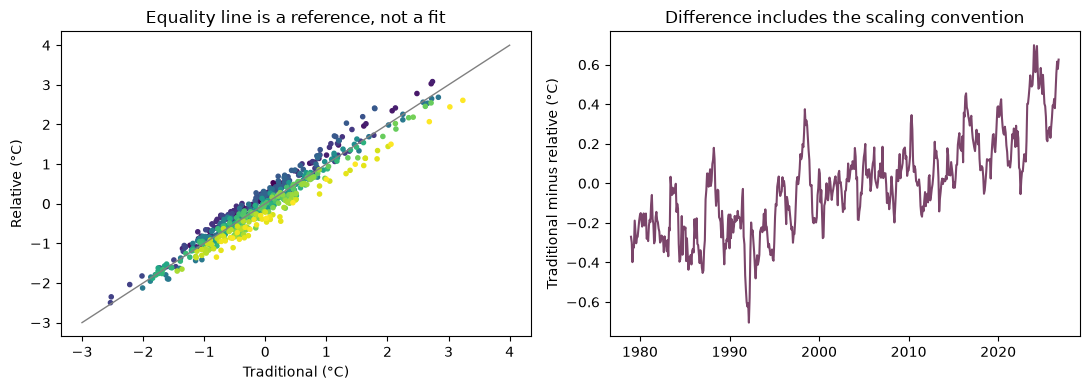

,date,anom_1991_2020,rnino_anom_1991_2020,difference
227,1997-12-01,2.8337,2.6859,0.1478
539,2023-12-01,2.0101,1.4452,0.5649
573,2026-10-01,3.2345,2.6089,0.6256


In [3]:
df["difference"] = df[ANOM] - df[REL]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(df[ANOM], df[REL], c=df.year, cmap="viridis", s=9)
axes[0].plot([-3,4], [-3,4], color="gray", lw=1)
axes[0].set(xlabel="Traditional (°C)", ylabel="Relative (°C)", title="Equality line is a reference, not a fit")
axes[1].plot(df.date, df.difference, color="#7b456a")
axes[1].set(ylabel="Traditional minus relative (°C)", title="Difference includes the scaling convention")
plt.tight_layout(); plt.show()
display(df.loc[df.date.isin(pd.to_datetime(["1997-12-01", "2023-12-01", "2026-10-01"])), ["date", ANOM, REL, "difference"]])

## Try it and explain

Repeat with nino4. Explain why traditional minus relative is not a direct estimate of tropical-mean warming.

**Interpretation check:** The relative column includes scaling. A difference between scaled and unscaled indices cannot be interpreted as the removed background alone.

## Transfer to the official tools

In Pulse select anomalies and enable relative. Keep the region and time aggregation fixed, then compare the official methodology before using thresholds.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [C3S Climate Pulse 2.0 announcement (10 November 2026)](https://climate.copernicus.eu/new-version-climate-pulse-provides-new-monitoring-el-nino-conditions)
- [Climate Pulse FAQs and methodology](https://pulse.climate.copernicus.eu/faqs)
- [Climate Pulse credits and citations](https://pulse.climate.copernicus.eu/credits)
- [ERA5 monthly data: C3S/ECMWF and ERA5 contributors](https://doi.org/10.24381/cds.f17050d7)
- [Hersbach et al. (2020): The ERA5 global reanalysis](https://doi.org/10.1002/qj.3803)
- [Tim Stockdale (2026): relative Niño indices and scaling](https://www.ecmwf.int/en/about/media-centre/science-blog/2026/measuring-strength-el-nino)
- [Method DOI](https://doi.org/10.21957/d05ccfe150)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](credits.md) and [data guide](data-guide.md).

**Continue:** [Days, seasons, and record claims](25-time-ranks-and-records.ipynb)